In [2]:
import pandas as pd
df = pd.read_csv('customer_churn.csv')
df.shape

(3941, 11)

In [3]:
#summary of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   str    
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   str    
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 338.8 KB


In [4]:
#description
df.describe()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
count,3747.000000,3772.000000,3941.000000,3941.000000,3941.000000,3941.000000,3728.000000,3941.000000,3941.000000
mean,10.081398,15.650583,3.679269,3.088302,4.237757,0.282416,4.531652,176.707419,0.171023
std,8.498864,8.452301,1.013938,1.381832,2.626699,0.450232,3.667648,48.791784,0.376576
min,0.000000,5.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,9.000000,3.000000,2.000000,2.000000,0.000000,2.000000,145.700000,0.000000
50%,9.000000,14.000000,4.000000,3.000000,3.000000,0.000000,3.000000,163.340000,0.000000
75%,16.000000,21.000000,4.000000,4.000000,6.000000,1.000000,7.000000,195.250000,0.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,1.000000,46.000000,324.990000,1.000000


In [5]:
#size of the datset
df.shape

(3941, 11)

In [6]:
df.columns

Index(['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered',
       'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus',
       'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount',
       'Churn'],
      dtype='str')

In [14]:
df['Churn'].unique()

array([0, 1])

In [15]:
df.isnull().sum()

Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

In [16]:
df['Tenure'] = df['Tenure'].fillna(df['Tenure'].median())
df['WarehouseToHome'] = df['WarehouseToHome'].fillna(df['WarehouseToHome'].median())
df['DaySinceLastOrder'] = df['DaySinceLastOrder'].fillna(df['DaySinceLastOrder'].median())

In [18]:
df.isnull().sum()

Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
dtype: int64

In [19]:
#find the duplucates
df[df.duplicated()]

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
70,1.0,11.0,4,Mobile Phone,5,Single,3,0,1.0,154.73,1
128,1.0,10.0,4,Mobile Phone,1,Single,3,1,1.0,140.69,1
194,18.0,26.0,3,Laptop & Accessory,3,Single,9,0,1.0,148.50,0
253,19.0,6.0,3,Fashion,5,Married,2,0,7.0,204.53,0
289,16.0,36.0,4,Laptop & Accessory,3,Married,4,0,3.0,170.56,0
...,...,...,...,...,...,...,...,...,...,...,...
3930,22.0,17.0,3,Laptop & Accessory,1,Single,4,0,4.0,145.07,0
3932,20.0,15.0,5,Laptop & Accessory,5,Married,10,1,8.0,171.15,0
3934,10.0,25.0,3,Laptop & Accessory,3,Married,4,0,2.0,157.68,0
3938,30.0,6.0,5,Laptop & Accessory,3,Married,3,1,2.0,156.60,0


In [20]:
#drop duplucates
df.drop_duplicates(inplace=True)

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.shape

(3269, 11)

In [23]:
corr=df.corr(numeric_only=True)


<Axes: >

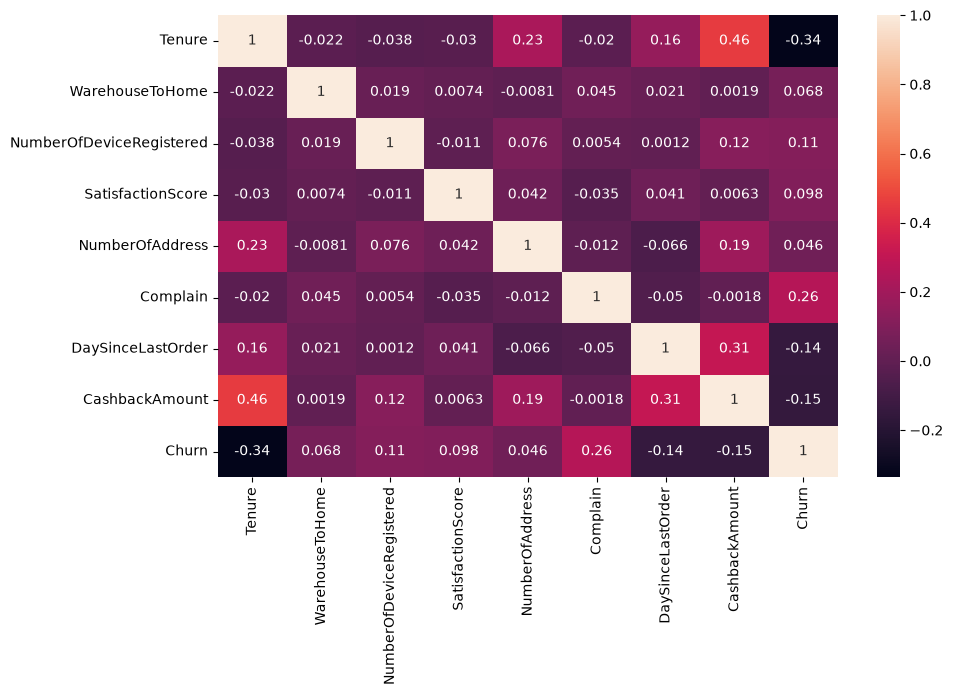

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True)

In [25]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

encoder = OneHotEncoder(sparse_output=False, drop='first', dtype=int)

encoded_array = encoder.fit_transform(df[['MaritalStatus', 'PreferedOrderCat']])

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(['MaritalStatus', 'PreferedOrderCat']),
    index=df.index
)

df = df.drop(columns=['MaritalStatus', 'PreferedOrderCat'])
df = pd.concat([df, encoded_df], axis=1)

In [26]:
df.info()

<class 'pandas.DataFrame'>
Index: 3269 entries, 0 to 3940
Data columns (total 16 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Tenure                               3269 non-null   float64
 1   WarehouseToHome                      3269 non-null   float64
 2   NumberOfDeviceRegistered             3269 non-null   int64  
 3   SatisfactionScore                    3269 non-null   int64  
 4   NumberOfAddress                      3269 non-null   int64  
 5   Complain                             3269 non-null   int64  
 6   DaySinceLastOrder                    3269 non-null   float64
 7   CashbackAmount                       3269 non-null   float64
 8   Churn                                3269 non-null   int64  
 9   MaritalStatus_Married                3269 non-null   int64  
 10  MaritalStatus_Single                 3269 non-null   int64  
 11  PreferedOrderCat_Grocery             3269 non-

In [27]:
df.head(5)

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,MaritalStatus_Married,MaritalStatus_Single,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others
0,15.0,29.0,4,3,2,0,7.0,143.32,0,0,1,0,1,0,0,0
1,7.0,25.0,4,1,2,0,7.0,129.29,0,1,0,0,0,1,0,0
2,27.0,13.0,3,1,5,0,7.0,168.54,0,1,0,0,1,0,0,0
3,20.0,25.0,4,3,7,0,3.0,230.27,0,0,0,0,0,0,0,0
4,30.0,15.0,4,4,8,0,8.0,322.17,0,0,1,0,0,0,0,1


In [28]:
# Quick stats check
df[['Tenure','WarehouseToHome','DaySinceLastOrder','CashbackAmount']].describe()

,Tenure,WarehouseToHome,DaySinceLastOrder,CashbackAmount
count,3269.000000,3269.000000,3269.000000,3269.00000
mean,10.127868,15.447537,4.460385,177.40115
std,8.438172,8.396214,3.610052,49.30914
min,0.000000,5.000000,0.000000,0.00000
25%,3.000000,9.000000,2.000000,145.89000
50%,9.000000,14.000000,3.000000,163.88000
75%,15.000000,20.000000,7.000000,197.13000
max,61.000000,127.000000,46.000000,324.99000


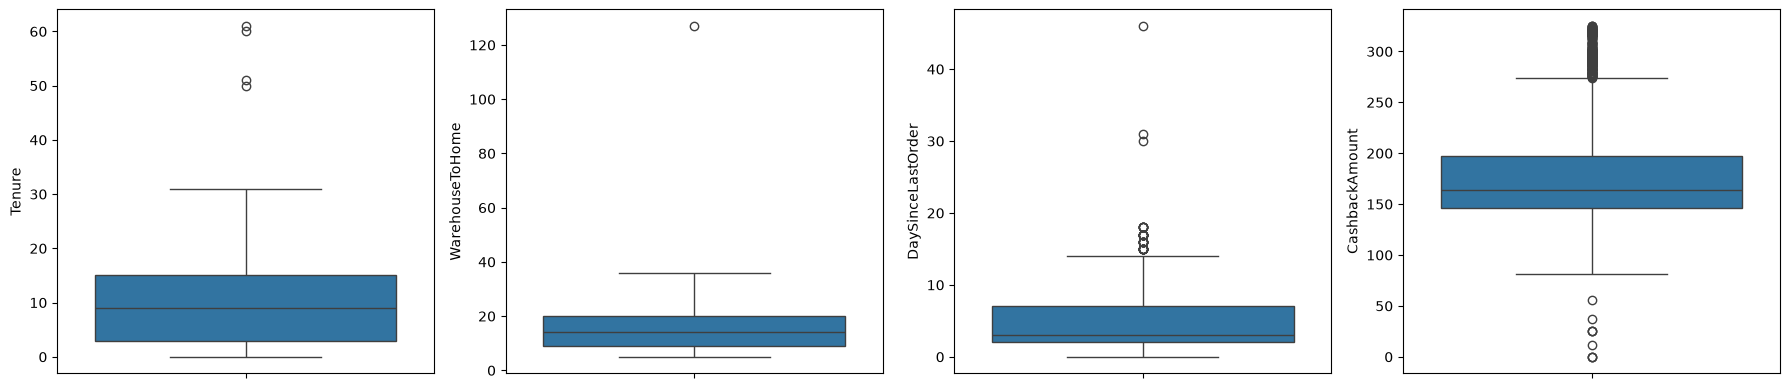

In [29]:
# Visual check
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(18,4))

sns.boxplot(y=df['Tenure'], ax=axes[0])
sns.boxplot(y=df['WarehouseToHome'], ax=axes[1])
sns.boxplot(y=df['DaySinceLastOrder'], ax=axes[2])
sns.boxplot(y=df['CashbackAmount'], ax=axes[3])

plt.tight_layout()
plt.show()

In [30]:
print(df['SatisfactionScore'].unique()) 

[3 1 4 2 5]


In [31]:
print(df['Complain'].unique())  

[0 1]


In [32]:
print(df['Tenure'].min())

0.0


In [33]:
print(df['WarehouseToHome'].min()) 

5.0


In [34]:
print(df['DaySinceLastOrder'].min())  

0.0


In [35]:
print(df['NumberOfAddress'].min())  

1


In [36]:
print(df.info())              

<class 'pandas.DataFrame'>
Index: 3269 entries, 0 to 3940
Data columns (total 16 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Tenure                               3269 non-null   float64
 1   WarehouseToHome                      3269 non-null   float64
 2   NumberOfDeviceRegistered             3269 non-null   int64  
 3   SatisfactionScore                    3269 non-null   int64  
 4   NumberOfAddress                      3269 non-null   int64  
 5   Complain                             3269 non-null   int64  
 6   DaySinceLastOrder                    3269 non-null   float64
 7   CashbackAmount                       3269 non-null   float64
 8   Churn                                3269 non-null   int64  
 9   MaritalStatus_Married                3269 non-null   int64  
 10  MaritalStatus_Single                 3269 non-null   int64  
 11  PreferedOrderCat_Grocery             3269 non-

In [38]:
print(df.shape)
print(df.duplicated().sum())
print(df.isnull().sum())

(3269, 16)
0
Tenure                                 0
WarehouseToHome                        0
NumberOfDeviceRegistered               0
SatisfactionScore                      0
NumberOfAddress                        0
Complain                               0
DaySinceLastOrder                      0
CashbackAmount                         0
Churn                                  0
MaritalStatus_Married                  0
MaritalStatus_Single                   0
PreferedOrderCat_Grocery               0
PreferedOrderCat_Laptop & Accessory    0
PreferedOrderCat_Mobile                0
PreferedOrderCat_Mobile Phone          0
PreferedOrderCat_Others                0
dtype: int64


In [40]:
## EDA
#target distribution
df['Churn'].value_counts()
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
0    83.664729
1    16.335271
Name: proportion, dtype: float64


In [41]:
#churn rate by complain
df.groupby('Complain')['Churn'].mean() * 100

Complain
0    10.264055
1    31.813246
Name: Churn, dtype: float64

In [42]:
#churn rate by satisficationlevel
df.groupby('SatisfactionScore')['Churn'].mean() * 100

SatisfactionScore
1    11.173975
2    13.010204
3    17.489270
4    15.920398
5    22.834646
Name: Churn, dtype: float64

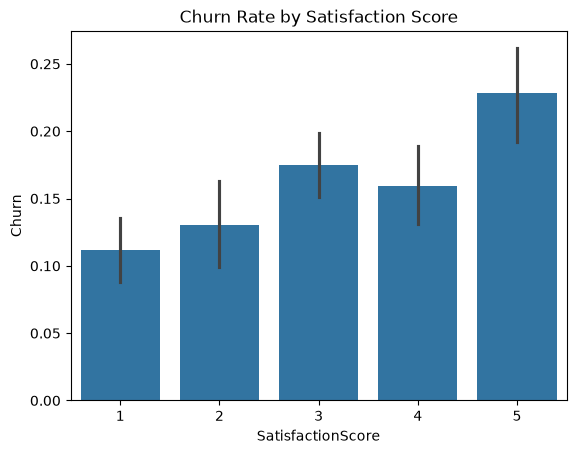

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(x='SatisfactionScore', y='Churn', data=df)
plt.title('Churn Rate by Satisfaction Score')
plt.show()

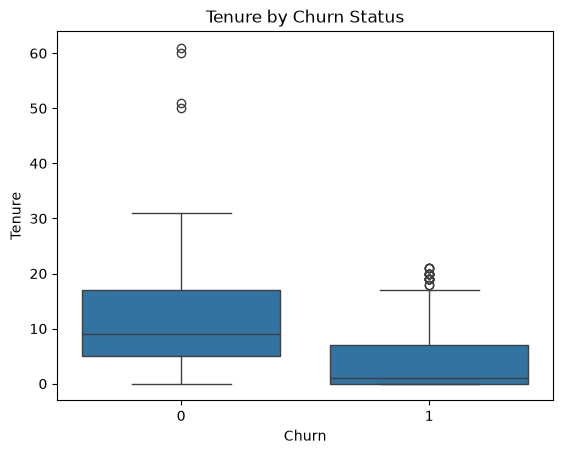

In [44]:
sns.boxplot(x='Churn', y='Tenure', data=df)
plt.title('Tenure by Churn Status')
plt.show()

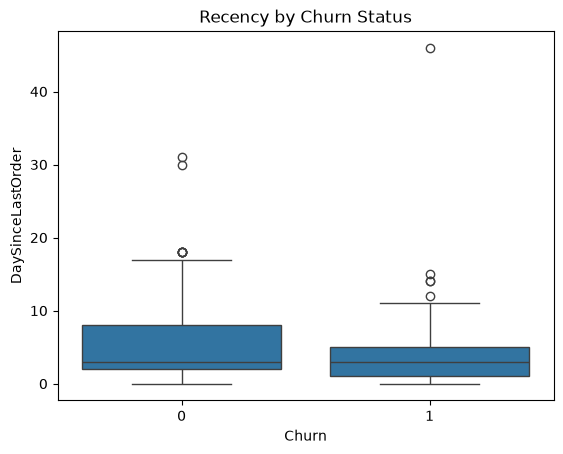

In [45]:
sns.boxplot(x='Churn', y='DaySinceLastOrder', data=df)
plt.title('Recency by Churn Status')
plt.show()

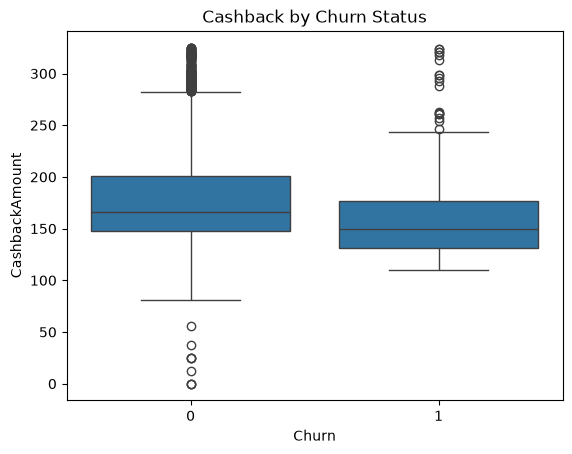

In [46]:
sns.boxplot(x='Churn', y='CashbackAmount', data=df)
plt.title('Cashback by Churn Status')
plt.show()

In [49]:
#churn rate by marital status
df.groupby('MaritalStatus_Married')['Churn'].mean() * 100

MaritalStatus_Married
0    22.109918
1    10.913405
Name: Churn, dtype: float64

In [50]:
df.groupby('MaritalStatus_Single')['Churn'].mean() * 100

MaritalStatus_Single
0    12.068966
1    25.918570
Name: Churn, dtype: float64

In [51]:
for col in ['PreferedOrderCat_Grocery','PreferedOrderCat_Laptop & Accessory',
            'PreferedOrderCat_Mobile','PreferedOrderCat_Mobile Phone','PreferedOrderCat_Others']:
    print(col, df.groupby(col)['Churn'].mean() * 100)

PreferedOrderCat_Grocery PreferedOrderCat_Grocery
0    17.299439
1     4.166667
Name: Churn, dtype: float64
PreferedOrderCat_Laptop & Accessory PreferedOrderCat_Laptop & Accessory
0    20.184825
1     9.810387
Name: Churn, dtype: float64
PreferedOrderCat_Mobile PreferedOrderCat_Mobile
0    14.585557
1    27.074236
Name: Churn, dtype: float64
PreferedOrderCat_Mobile Phone PreferedOrderCat_Mobile Phone
0    13.325472
1    26.896552
Name: Churn, dtype: float64
PreferedOrderCat_Others PreferedOrderCat_Others
0    16.762821
1     7.382550
Name: Churn, dtype: float64


In [52]:
df.corr()['Churn'].sort_values(ascending=False)

Churn                                  1.000000
Complain                               0.262217
MaritalStatus_Single                   0.172961
PreferedOrderCat_Mobile Phone          0.152508
PreferedOrderCat_Mobile                0.117255
NumberOfDeviceRegistered               0.109660
SatisfactionScore                      0.098498
WarehouseToHome                        0.067914
NumberOfAddress                        0.046344
PreferedOrderCat_Others               -0.052922
PreferedOrderCat_Grocery              -0.092654
PreferedOrderCat_Laptop & Accessory   -0.135568
DaySinceLastOrder                     -0.143244
MaritalStatus_Married                 -0.151357
CashbackAmount                        -0.151359
Tenure                                -0.336335
Name: Churn, dtype: float64

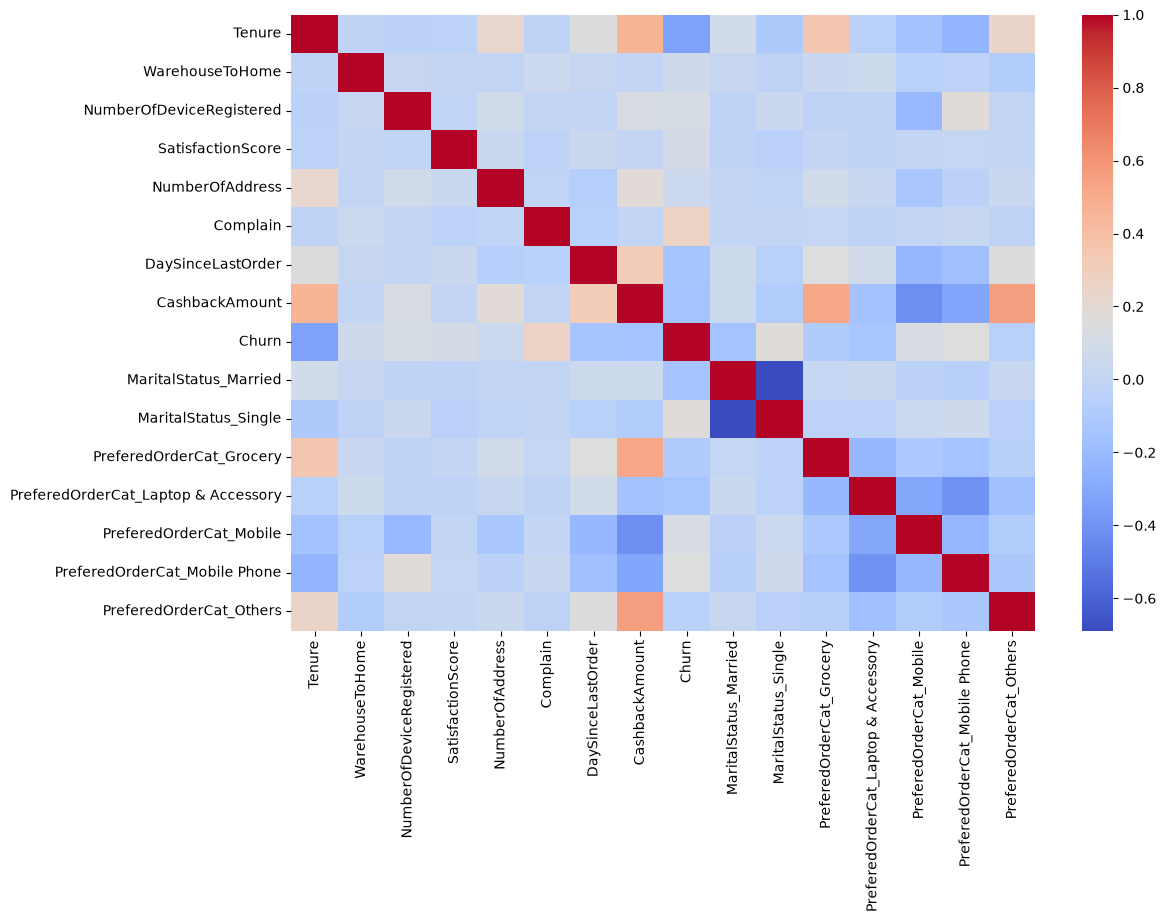

In [53]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.show()

In [54]:
df.groupby('Churn').mean()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,MaritalStatus_Married,MaritalStatus_Single,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others
Churn,,,,,,,,,,,,,,,
0,11.381718,15.195612,3.627057,2.959781,4.169287,0.229616,4.688848,180.698468,0.549177,0.272761,0.084095,0.400000,0.122121,0.193784,0.050457
1,3.705993,16.737828,3.928839,3.331461,4.498127,0.548689,3.290262,160.513202,0.344569,0.488764,0.018727,0.222846,0.232210,0.365169,0.020599


In [55]:
def detect_outliers_iqr(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(f"{column}: {len(outliers)} outliers (bounds: {lower:.2f} to {upper:.2f})")
    return outliers

for col in ['Tenure','WarehouseToHome','DaySinceLastOrder','CashbackAmount']:
    detect_outliers_iqr(col)

Tenure: 4 outliers (bounds: -15.00 to 33.00)
WarehouseToHome: 1 outliers (bounds: -7.50 to 36.50)
DaySinceLastOrder: 40 outliers (bounds: -5.50 to 14.50)
CashbackAmount: 253 outliers (bounds: 69.03 to 273.99)


In [56]:
df[df['CashbackAmount'] > 273.99]['CashbackAmount'].describe()

count    244.000000
mean     298.264180
std       13.652028
min      274.260000
25%      289.445000
50%      295.455000
75%      308.030000
max      324.990000
Name: CashbackAmount, dtype: float64

In [57]:
df[df['CashbackAmount'] > 273.99]['Churn'].mean() * 100

np.float64(4.508196721311475)

In [58]:
df.to_csv('customer_churn_cleaned.csv', index=False)

In [60]:
for col in df.columns:
    print(col, ':', df[col].unique())

Tenure : [15.  7. 27. 20. 30.  1. 11. 17.  6. 16. 10.  9.  8. 19.  0.  3.  5. 18.
 12. 24.  4. 61. 25. 13. 14.  2. 21. 29. 26. 23. 31. 22. 28. 51. 60. 50.]
WarehouseToHome : [ 29.  25.  13.  15.  16.  11.  12.   7.  26.  20.  14.   8.  21.  22.
  27.  18.  33.   9.  17.   6.  31.  28.  10.  19.  32.  23.  30.  35.
  34.  24.   5.  36. 127.]
NumberOfDeviceRegistered : [4 3 6 2 5 1]
SatisfactionScore : [3 1 4 2 5]
NumberOfAddress : [ 2  5  7  8  3  1  9  4 10 11  6 19 22 21]
Complain : [0 1]
DaySinceLastOrder : [ 7.  3.  8. 11.  2.  1.  4.  6.  0. 14.  9. 10. 12.  5. 17. 30. 18. 16.
 13. 15. 46. 31.]
CashbackAmount : [143.32 129.29 168.54 ... 147.66 231.86 153.73]
Churn : [0 1]
MaritalStatus_Married : [0 1]
MaritalStatus_Single : [1 0]
PreferedOrderCat_Grocery : [0 1]
PreferedOrderCat_Laptop & Accessory : [1 0]
PreferedOrderCat_Mobile : [0 1]
PreferedOrderCat_Mobile Phone : [0 1]
PreferedOrderCat_Others : [0 1]


In [63]:
df.to_excel('customer_churn_cleaned.xlsx', index=False, sheet_name='CleanedData')

In [62]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   ---------------------------------------- 0/2 [et-xmlfile]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ----------------